In [ ]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [ ]:
df=pd.read_csv("/content/Car details v3.csv")
print("Datase Loaded Successfully")

Datase Loaded Successfully


In [ ]:
df.shape

(8128, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


In [ ]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,221
engine,221


In [ ]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [ ]:
print("No.of records:",df.duplicated().sum())

No.of records: 0


In [ ]:
# Convert text-based numerical columns into numeric values
for col in ['mileage', 'engine', 'max_power']:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.extract(r'([-+]?\d*\.?\d+)', expand=False),
        errors='coerce'
    )

# Remove rows with missing selling price
df.dropna(subset=['selling_price'], inplace=True)

# Remove invalid prices
df = df[df['selling_price'] > 0].copy()

print(df.head())

                           name  year  selling_price  km_driven    fuel  \
0        Maruti Swift Dzire VDI  2014         450000     145500  Diesel   
1  Skoda Rapid 1.5 TDI Ambition  2014         370000     120000  Diesel   
2      Honda City 2017-2020 EXi  2006         158000     140000  Petrol   
3     Hyundai i20 Sportz Diesel  2010         225000     127000  Diesel   
4        Maruti Swift VXI BSIII  2007         130000     120000  Petrol   

  seller_type transmission         owner  mileage  engine  max_power  \
0  Individual       Manual   First Owner    23.40  1248.0      74.00   
1  Individual       Manual  Second Owner    21.14  1498.0     103.52   
2  Individual       Manual   Third Owner    17.70  1497.0      78.00   
3  Individual       Manual   First Owner    23.00  1396.0      90.00   
4  Individual       Manual   First Owner    16.10  1298.0      88.20   

                     torque  seats price_category  
0            190Nm@ 2000rpm    5.0         Medium  
1       250N

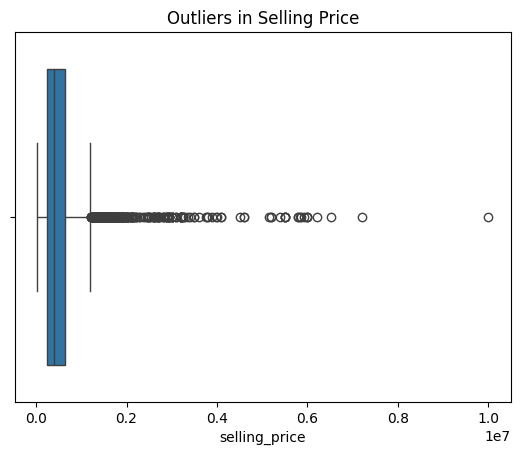

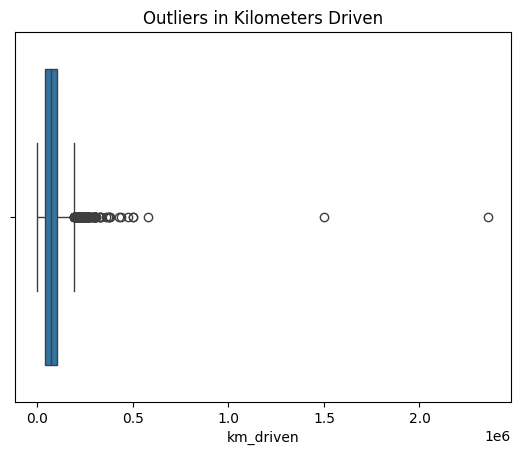

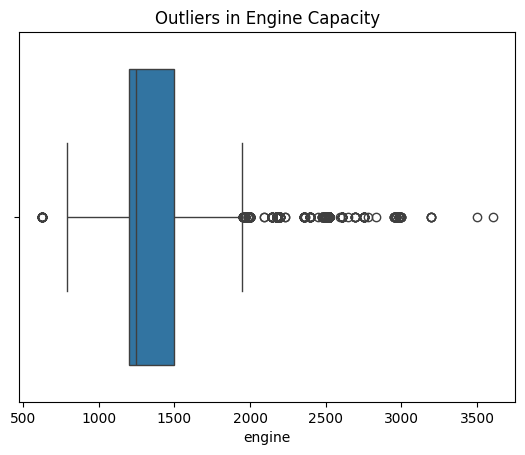

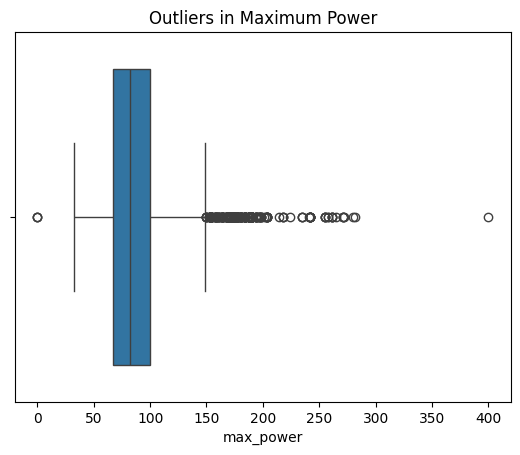

In [ ]:
# Identify outliers in selling price
sns.boxplot(x=df['selling_price'])
plt.title("Outliers in Selling Price")
plt.show()

# Identify outliers in km_driven
sns.boxplot(x=df['km_driven'])
plt.title("Outliers in Kilometers Driven")
plt.show()

# Identify outliers in engine
sns.boxplot(x=df['engine'])
plt.title("Outliers in Engine Capacity")
plt.show()

# Identify outliers in max_power
sns.boxplot(x=df['max_power'])
plt.title("Outliers in Maximum Power")
plt.show()

In [ ]:
# Remove outliers using IQR method

outlier_cols = [
    'selling_price',
    'km_driven',
    'engine',
    'max_power'
]

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df = df[
        (df[col] >= lower_limit) &
        (df[col] <= upper_limit)
    ]

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (5153, 14)


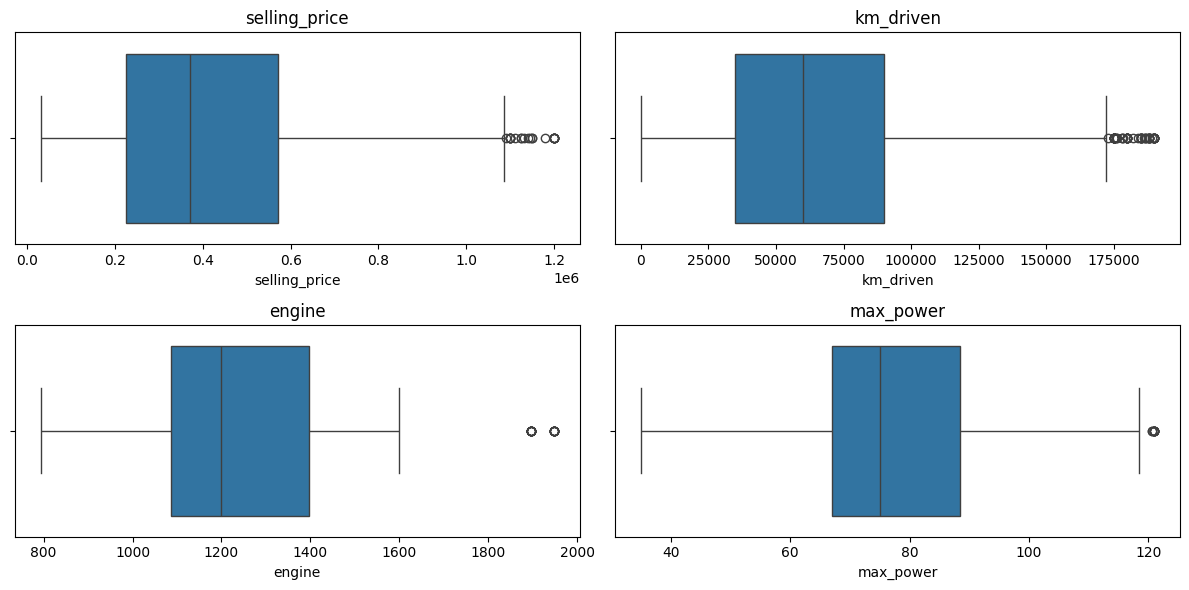

In [ ]:
# Check boxplots after removing outliers
plt.figure(figsize=(12, 6))

for i, col in enumerate(outlier_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
# Fill missing numerical values with median
numeric_cols = [
    'year', 'selling_price', 'km_driven',
    'mileage', 'engine', 'max_power', 'seats'
]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
categorical_cols = [
    'fuel', 'seller_type', 'transmission', 'owner'
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
name              0
year              0
selling_price     0
km_driven         0
fuel              0
seller_type       0
transmission      0
owner             0
mileage           0
engine            0
max_power         0
torque            0
seats             0
price_category    0
dtype: int64


In [ ]:
# Convert selling price into three classes
df['price_category'] = pd.qcut(
    df['selling_price'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

print(df[['selling_price', 'price_category']].head())
print(df['price_category'].value_counts())

   selling_price price_category
0         450000         Medium
1         370000         Medium
2         158000            Low
3         225000            Low
4         130000            Low
price_category
Medium    1783
Low       1730
High      1640
Name: count, dtype: int64


In [ ]:
# Select input features
x = df[
    [
        'year', 'km_driven', 'mileage',
        'engine', 'max_power', 'seats',
        'fuel', 'seller_type', 'transmission', 'owner'
    ]
]

# Convert categorical features into numerical columns
x = pd.get_dummies(x, dtype=int)

# Target variable
y = df['price_category']

print("Input shape:", x.shape)
print("Target shape:", y.shape)

Input shape: (5153, 19)
Target shape: (5153,)


In [ ]:
# Split the data into training and testing
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=15,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (4122, 19)
Testing data: (1031, 19)


In [ ]:
# Standardization
mean = x_train.mean()
std = x_train.std().replace(0, 1)

x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

print("Standardization completed")

Standardization completed


In [ ]:
# Model building
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(x_train, y_train)

print("KNN model trained successfully")

KNN model trained successfully


In [ ]:
# Predictions on test data
y_pred = knn.predict(x_test)

print("Actual values:")
print(y_test.head(10).to_list())

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
['Medium', 'High', 'Low', 'Medium', 'Low', 'Low', 'Low', 'Low', 'Medium', 'High']

Predicted values:
['Medium' 'High' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'Medium' 'High']


In [ ]:
# Evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=['Low', 'Medium', 'High']))

Accuracy: 0.7885548011639185

Classification Report:
              precision    recall  f1-score   support

        High       0.84      0.86      0.85       328
         Low       0.82      0.84      0.83       346
      Medium       0.71      0.68      0.69       357

    accuracy                           0.79      1031
   macro avg       0.79      0.79      0.79      1031
weighted avg       0.79      0.79      0.79      1031


Confusion Matrix:
[[289  54   3]
 [ 64 243  50]
 [  1  46 281]]


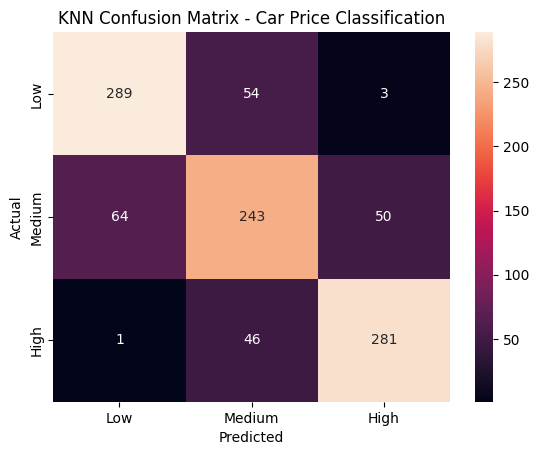

In [ ]:
# Confusion matrix
cm = confusion_matrix(
    y_test, y_pred,
    labels=['Low', 'Medium', 'High']
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix - Car Price Classification")
plt.show()

In [ ]:
# Evaluate KNN for different K values
k_values = [3, 5, 7, 9, 11]
accuracy_values = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train, y_train)

    predictions = model.predict(x_test)
    accuracy = accuracy_score(y_test, predictions)

    accuracy_values.append(accuracy)

    print("K =", k, "Accuracy =", round(accuracy * 100, 2), "%")

K = 3 Accuracy = 78.37 %
K = 5 Accuracy = 78.86 %
K = 7 Accuracy = 77.4 %
K = 9 Accuracy = 76.92 %
K = 11 Accuracy = 76.92 %


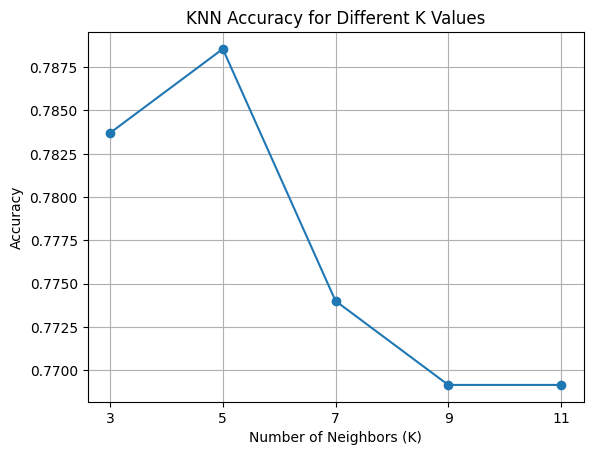

In [ ]:
# Plot accuracy for different K values
plt.plot(k_values, accuracy_values, marker='o')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(k_values)
plt.grid()
plt.show()